**Use Sentinel 2 data to classify a patch as urban or forested area. This task is very similar to the one you did in Lab-3. You can see why, if possible, we prefer Bayesian classifiers.**

## Rationale
I have used patches as training samples as it was suggested in the exercise steps. However my first idea was to not feed patch on input and treat it as single record. But rather to treat pixel as a single record in dataset. In that case the ANN would be much smaller.

However I have sticked to approach described in the exercise description. I have stumbled upon a problem where after ANN training I was receiving constant probas for classes. I could not receive anything else even after changing layers, epochs, activation functions, optimizers. Finally I saw that tanh function is being saturated cause of the large input size, resulting in 1 or -1 values. I started to read what should I do in that case and I decided to use normalization.

Essentially whole normalization process in my case is to transform each "sample" in dataset in such a way:
- subtract mean
- divide by std

This allowed me to obtain sensible results and working network for patch size of 200 just for one layered network with 32 neurons.

## Posing the task as a function

We want a mapping: $$f: \mathbb{R}^{200 \times 200 \times 3} \rightarrow \{0, 1\}$$

where the input is a Sentinel-2 RGB patch and the output is the class label (0 = forest, 1 = urban).

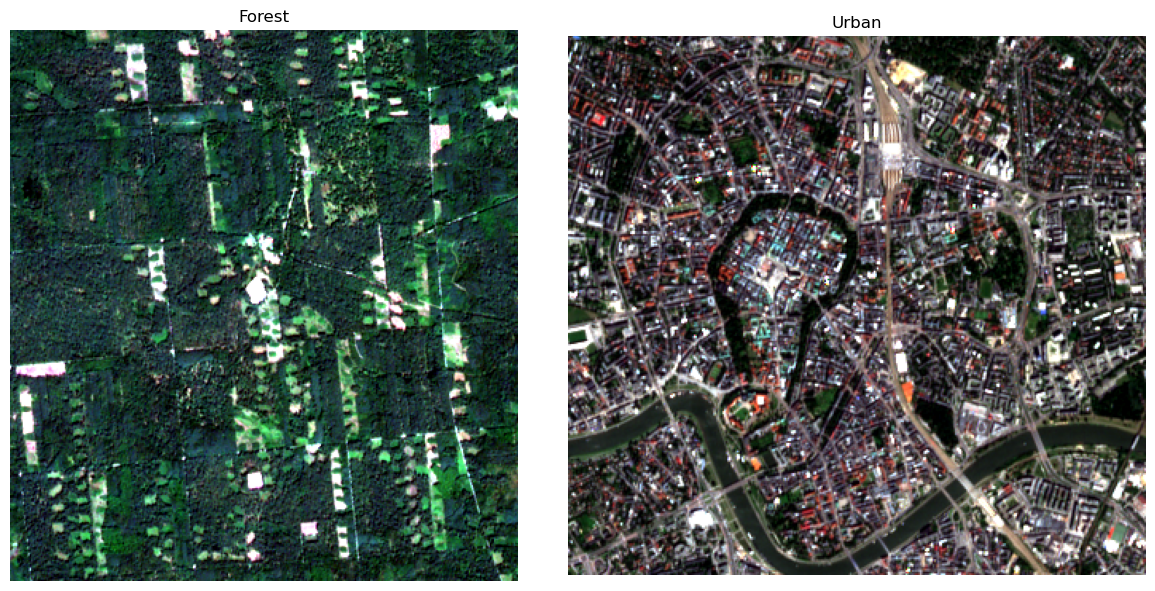

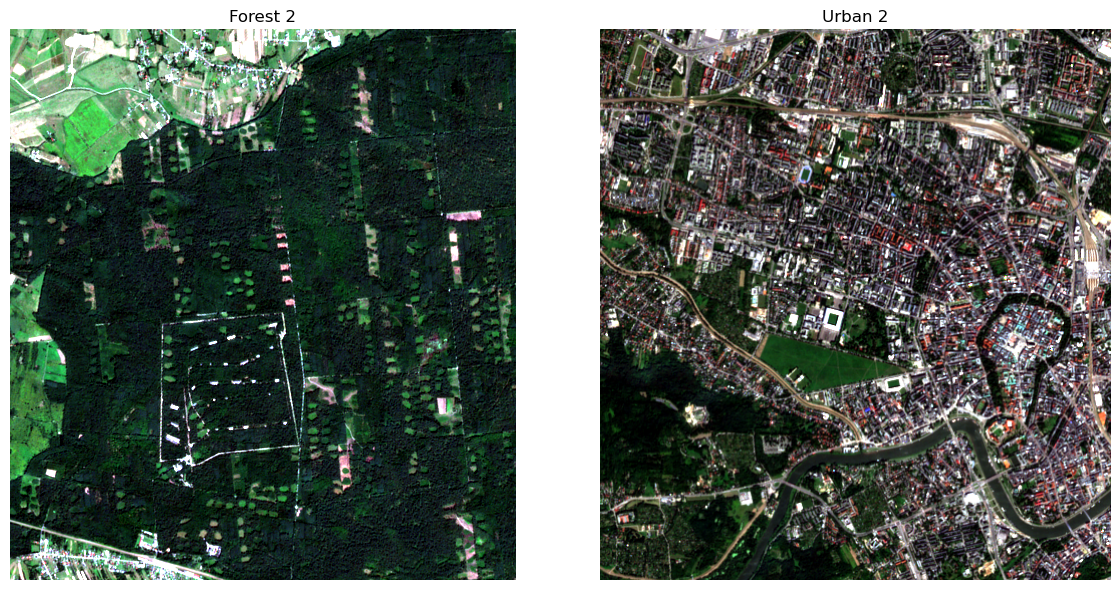

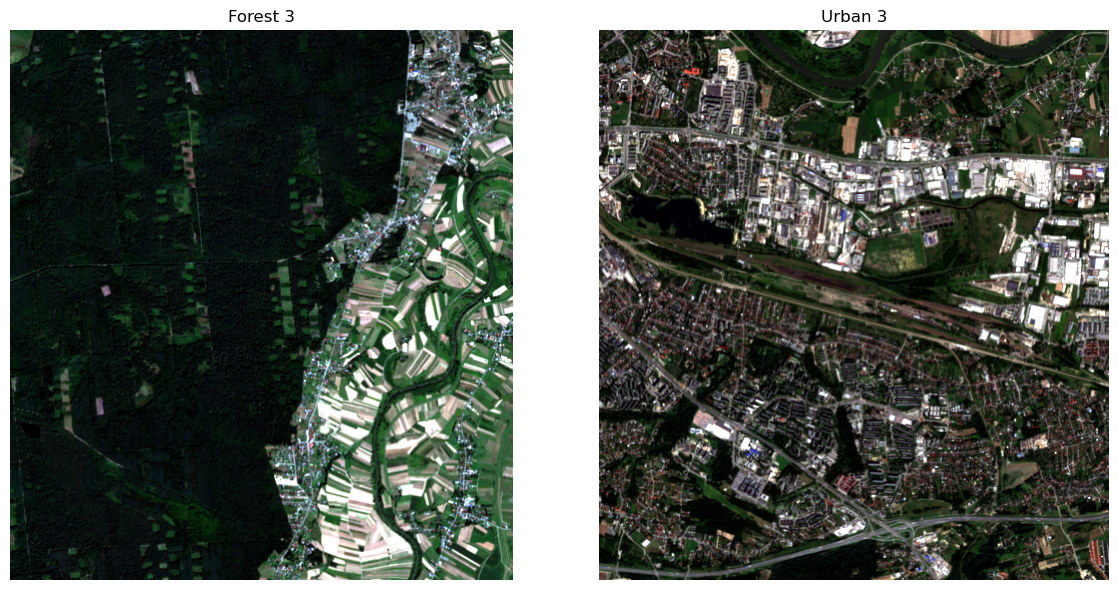

In [253]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from sklearn.model_selection import train_test_split

DATA = Path("./scenes")
S2_BANDS = ["B04", "B03", "B02"]
PATCH = 200
LABELS = {"forest": 0, "urban": 1}
FOREST_SCENES = ["s2_forest", "s2_forest2", "s2_forest3"]
URBAN_SCENES = ["s2_urban", "s2_urban2", "s2_urban3"]


def percentile_stretch(array: np.ndarray, lower: int = 2, upper: int = 98) -> np.ndarray:
    lo, hi = np.percentile(array, (lower, upper))
    return np.clip((array - lo) / (hi - lo + 1e-6), 0, 1)


def get_raster_image(filename: str) -> np.ndarray:
    bands = []
    for band in S2_BANDS:
        with rasterio.open(DATA / f"{filename}_{band}.tif") as src:
            bands.append(src.read(1).astype(np.float32) / 10000.0)
    return np.dstack(bands)


def to_rgb(image: np.ndarray) -> np.ndarray:
    return np.dstack([percentile_stretch(image[:, :, i]) for i in range(image.shape[-1])])


def display_raster_image(
    first_image: np.ndarray,
    second_image: np.ndarray,
    first_title: str = "",
    second_title: str = "",
):
    _, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(to_rgb(first_image))
    ax[1].imshow(to_rgb(second_image))
    ax[0].set_title(first_title)
    ax[1].set_title(second_title)
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()


forest_images = {name: get_raster_image(name) for name in FOREST_SCENES}
urban_images = {name: get_raster_image(name) for name in URBAN_SCENES}
s2_mixed = get_raster_image("s2_mixed")

display_raster_image(forest_images["s2_forest"], urban_images["s2_urban"], "Forest", "Urban")
display_raster_image(forest_images["s2_forest2"], urban_images["s2_urban2"], "Forest 2", "Urban 2")
display_raster_image(forest_images["s2_forest3"], urban_images["s2_urban3"], "Forest 3", "Urban 3")


X (patches): (852, 200, 200, 3) y: (852,)
X_flat: (852, 120000) → ANN input size 120000
train/test: (639, 120000) (213, 120000)
class counts: {'forest': 446, 'urban': 406}
mixed patches for eval: (240, 200, 200, 3)


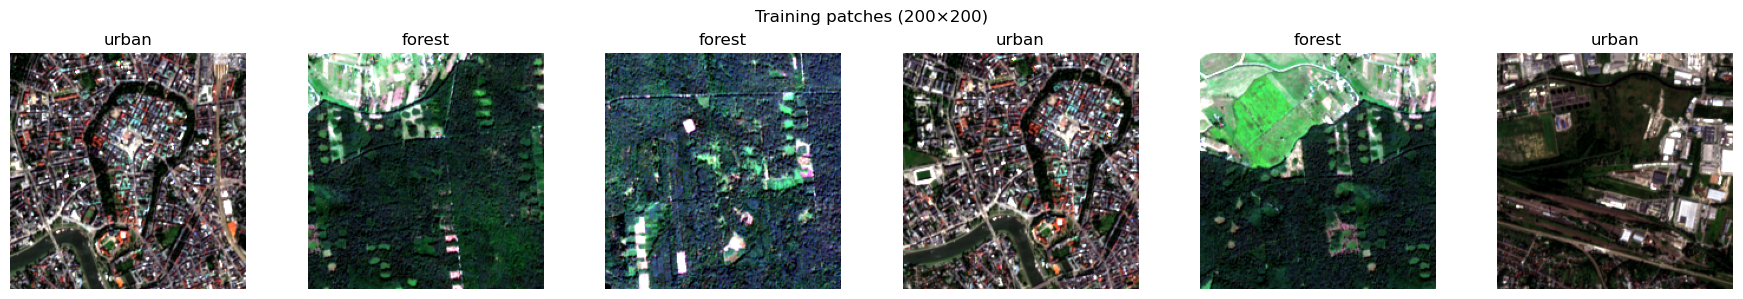

In [254]:
def extract_patches(img: np.ndarray, patch: int = PATCH, stride: int = 25) -> np.ndarray:
    H, W, _ = img.shape
    patches = [
        img[r : r + patch, c : c + patch]
        for r in range(0, H - patch + 1, stride)
        for c in range(0, W - patch + 1, stride)
    ]
    if not patches:
        raise ValueError(f"Image {img.shape} is smaller than patch {patch}")
    return np.stack(patches, axis=0)


X_forest = np.concatenate([extract_patches(img) for img in forest_images.values()], axis=0)
X_urban = np.concatenate([extract_patches(img) for img in urban_images.values()], axis=0)

y_forest = np.full(len(X_forest), LABELS["forest"], dtype=np.float32)
y_urban = np.full(len(X_urban), LABELS["urban"], dtype=np.float32)

X = np.concatenate([X_forest, X_urban], axis=0)
y = np.concatenate([y_forest, y_urban], axis=0)

rng = np.random.default_rng(42)
perm = rng.permutation(len(X))
X, y = X[perm], y[perm]

X_flat = X.reshape(len(X), -1).astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y, test_size=0.25, random_state=42, stratify=y
)

mu = X_train.mean()
std = X_train.std()

X_train = (X_train - mu) / std
X_test = (X_test - mu) / std


print("X (patches):", X.shape, "y:", y.shape)
print("X_flat:", X_flat.shape, "→ ANN input size", X_flat.shape[1])
print("train/test:", X_train.shape, X_test.shape)
print("class counts:", {name: int((y == lab).sum()) for name, lab in LABELS.items()})

mixed_patches = extract_patches(s2_mixed)
mixed_flat = (mixed_patches.reshape(len(mixed_patches), -1).astype(np.float32) - mu) / std
print("mixed patches for eval:", mixed_patches.shape)

n_show = min(6, len(X))
fig, axes = plt.subplots(1, n_show, figsize=(3 * n_show, 3))
for ax, patch, label in zip(axes, X[:n_show], y[:n_show]):
    ax.imshow(to_rgb(patch))
    ax.set_title("forest" if label == 0 else "urban")
    ax.axis("off")
plt.suptitle("Training patches (200×200)")
plt.tight_layout()
plt.show()


In [ ]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

def obtain_model(layers, loss="mse", optimizer=None, epochs=200, batch_size=32):
    if optimizer is None:
        optimizer = tf.keras.optimizers.Adam(0.01)

    input_dim = X_train.shape[1]
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(input_dim,)), *layers])
    model.compile(loss=loss, optimizer=optimizer)
    model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=False)

    return model

In [256]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score

def eval(model, X_train, X_test, y_train, y_test):
    train_pred = (model.predict(X_train, verbose=0) >= 0.5).ravel()
    test_pred = (model.predict(X_test, verbose=0) >= 0.5).ravel()

    print("Train accuracy:", (train_pred == y_train).mean())
    print("Test accuracy:", (test_pred == y_test).mean())
    print("Test F1:", f1_score(y_test, test_pred))
    print("Test recall:", recall_score(y_test, test_pred))
    print("Test precision:", precision_score(y_test, test_pred))

    print(confusion_matrix(y_test, test_pred))

In [257]:
model_v1 = obtain_model([tf.keras.layers.Dense(units=32, activation="tanh"), tf.keras.layers.Dense(units=1, activation="sigmoid")])

print("Dense(32, tanh)")
eval(model_v1, X_train, X_test, y_train, y_test)
print("----------")

model_v2 = obtain_model([tf.keras.layers.Dense(units=128, activation="tanh"), tf.keras.layers.Dense(units=1, activation="sigmoid")])

print("Dense(128, tanh)")
eval(model_v2, X_train, X_test, y_train, y_test)
print("----------")

model_v3 = obtain_model([
    tf.keras.layers.Dense(units=64, activation="tanh"),
    tf.keras.layers.Dense(units=32, activation="tanh"),
    tf.keras.layers.Dense(units=1, activation="sigmoid"),
])

print("Dense(64, tanh) → Dense(32, tanh)")
eval(model_v3, X_train, X_test, y_train, y_test)
print("----------")

model_v4 = obtain_model(
    [tf.keras.layers.Dense(units=32, activation="tanh"), tf.keras.layers.Dense(units=1, activation="sigmoid")],
    optimizer=tf.keras.optimizers.SGD(0.01),
)

print("SGD(0.01)")
eval(model_v4, X_train, X_test, y_train, y_test)
print("----------")

model_v5 = obtain_model(
    [tf.keras.layers.Dense(units=32, activation="relu"), tf.keras.layers.Dense(units=1, activation="sigmoid")],
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.Adam(0.001),
)

print("Dense(32, relu) + binary_crossentropy + Adam(0.001)")
eval(model_v5, X_train, X_test, y_train, y_test)
print("----------")


Dense(32, tanh)
Train accuracy: 0.9593114241001565
Test accuracy: 0.9483568075117371
Test F1: 0.9473684210526315
Test recall: 0.9801980198019802
Test precision: 0.9166666666666666
[[103   9]
 [  2  99]]
----------
Dense(128, tanh)
Train accuracy: 0.9436619718309859
Test accuracy: 0.9295774647887324
Test F1: 0.9289099526066351
Test recall: 0.9702970297029703
Test precision: 0.8909090909090909
[[100  12]
 [  3  98]]
----------
Dense(64, tanh) → Dense(32, tanh)
Train accuracy: 0.9624413145539906
Test accuracy: 0.9530516431924883
Test F1: 0.9523809523809523
Test recall: 0.9900990099009901
Test precision: 0.9174311926605505
[[103   9]
 [  1 100]]
----------
SGD(0.01)
Train accuracy: 1.0
Test accuracy: 0.9812206572769953
Test F1: 0.9801980198019802
Test recall: 0.9801980198019802
Test precision: 0.9801980198019802
[[110   2]
 [  2  99]]
----------
Dense(32, relu) + binary_crossentropy + Adam(0.001)
Train accuracy: 1.0
Test accuracy: 0.9906103286384976
Test F1: 0.9900990099009901
Test recall:

## Summary
I have tested various settings for our ANN and obtained different results for selected NN structure, activations and optimizers. I have added additional metrics such as f1, recall or precision because I remembered them from my bachelor ML course. The best result so far occured to be model V5 with Dense(32, relu) + binary_crossentropy + Adam(0.001) and 200 epochs.

I think the Bayes approach is much simpler and more straightforward. We do not have training phase per-se, we don't need to come up with proper parameters and network architecture. ANN works quite well however, I wonder if the results would be comparable if I would have posed the function as single pixel on input.